In [1]:

# SoundSense - Step 2: Download ESC-50 Dataset

!wget -q https://github.com/karolpiczak/ESC-50/archive/refs/heads/master.zip -O esc50.zip

!unzip -q -o esc50.zip

import os

DATASET_PATH = "/content/ESC-50-master"
AUDIO_PATH = os.path.join(DATASET_PATH, "audio")
METADATA_PATH = os.path.join(DATASET_PATH, "meta", "esc50.csv")

print("Dataset folder exists:", os.path.exists(DATASET_PATH))
print("Audio folder exists:", os.path.exists(AUDIO_PATH))
print("Metadata file exists:", os.path.exists(METADATA_PATH))

if os.path.exists(AUDIO_PATH):
    print("Total audio files:", len(os.listdir(AUDIO_PATH)))


Dataset folder exists: True
Audio folder exists: True
Metadata file exists: True
Total audio files: 2000


In [2]:

# SoundSense - Step 2: Download ESC-50 Dataset

!wget -q https://github.com/karolpiczak/ESC-50/archive/refs/heads/master.zip -O esc50.zip

!unzip -q -o esc50.zip

import os

DATASET_PATH = "/content/ESC-50-master"
AUDIO_PATH = os.path.join(DATASET_PATH, "audio")
METADATA_PATH = os.path.join(DATASET_PATH, "meta", "esc50.csv")

print("Dataset folder exists:", os.path.exists(DATASET_PATH))
print("Audio folder exists:", os.path.exists(AUDIO_PATH))
print("Metadata file exists:", os.path.exists(METADATA_PATH))

if os.path.exists(AUDIO_PATH):
    print("Total audio files:", len(os.listdir(AUDIO_PATH)))


Dataset folder exists: True
Audio folder exists: True
Metadata file exists: True
Total audio files: 2000


In [3]:

import pandas as pd
import os

DATASET_PATH = "/content/ESC-50-master"
AUDIO_PATH = os.path.join(DATASET_PATH, "audio")
METADATA_PATH = os.path.join(DATASET_PATH, "meta", "esc50.csv")

# Load labels
df = pd.read_csv(METADATA_PATH)

print("Total audio records:", len(df))
print("Total sound categories:", df["category"].nunique())
print("\nRecordings per category:")
print(df["category"].value_counts().sort_index())

print("\nMissing values:")
print(df.isnull().sum())

# Verify a sample audio file
sample = df.iloc[0]
sample_path = os.path.join(AUDIO_PATH, sample["filename"])

print("\nSample filename:", sample["filename"])
print("Sample category:", sample["category"])
print("Audio exists:", os.path.exists(sample_path))



Total audio records: 2000
Total sound categories: 50

Recordings per category:
category
airplane            40
breathing           40
brushing_teeth      40
can_opening         40
car_horn            40
cat                 40
chainsaw            40
chirping_birds      40
church_bells        40
clapping            40
clock_alarm         40
clock_tick          40
coughing            40
cow                 40
crackling_fire      40
crickets            40
crow                40
crying_baby         40
dog                 40
door_wood_creaks    40
door_wood_knock     40
drinking_sipping    40
engine              40
fireworks           40
footsteps           40
frog                40
glass_breaking      40
hand_saw            40
helicopter          40
hen                 40
insects             40
keyboard_typing     40
laughing            40
mouse_click         40
pig                 40
pouring_water       40
rain                40
rooster             40
sea_waves           40
sheep          

In [4]:

# SoundSense - Step 5: Prepare the 10-class dataset

!pip -q install librosa tqdm

import os
import numpy as np
import pandas as pd
import librosa
from tqdm.auto import tqdm

# 1. Dataset paths
DATASET_PATH = "/content/ESC-50-master"
AUDIO_PATH = os.path.join(DATASET_PATH, "audio")
METADATA_PATH = os.path.join(DATASET_PATH, "meta", "esc50.csv")

# 2. Our FINAL 10 sound categories
selected_categories = [
    "dog",
    "cat",
    "chirping_birds",
    "rain",
    "thunderstorm",
    "car_horn",
    "siren",
    "airplane",
    "sea_waves",
    "crying_baby"
]

# 3. Load and filter metadata
df = pd.read_csv(METADATA_PATH)
df = df[df["category"].isin(selected_categories)].copy()

# Keep label order consistent
label_to_id = {
    category: i
    for i, category in enumerate(selected_categories)
}

df["label"] = df["category"].map(label_to_id)
df = df.sort_values(["fold", "filename"]).reset_index(drop=True)

print("Selected recordings:", len(df))
print("Selected categories:", df["category"].nunique())
print("\nRecordings per category:")
print(df["category"].value_counts().reindex(selected_categories))

# 4. Convert each audio into a Mel spectrogram
X = []
y = []
folds = []
filenames = []

for _, row in tqdm(df.iterrows(), total=len(df)):
    file_path = os.path.join(AUDIO_PATH, row["filename"])

    # Load audio at a consistent sample rate
    audio, sr = librosa.load(file_path, sr=22050, mono=True)

    # Create 128-band Mel spectrogram
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=2048,
        hop_length=512,
        n_mels=128
    )

    # Convert power to decibels
    mel_db = librosa.power_to_db(mel, ref=np.max)

    X.append(mel_db)
    y.append(row["label"])
    folds.append(row["fold"])
    filenames.append(row["filename"])

# 5. Convert lists to NumPy arrays
X = np.array(X, dtype=np.float32)
X = X[..., np.newaxis]  # Add CNN channel dimension

y = np.array(y, dtype=np.int64)
folds = np.array(folds, dtype=np.int64)
filenames = np.array(filenames)

# 6. Save prepared data
np.savez_compressed(
    "/content/soundsense_10class_data.npz",
    X=X,
    y=y,
    folds=folds,
    filenames=filenames,
    categories=np.array(selected_categories)
)

print("\nPREPROCESSING COMPLETE!")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Number of classes:", len(np.unique(y)))
print("Saved file: /content/soundsense_10class_data.npz")


Selected recordings: 400
Selected categories: 10

Recordings per category:
category
dog               40
cat               40
chirping_birds    40
rain              40
thunderstorm      40
car_horn          40
siren             40
airplane          40
sea_waves         40
crying_baby       40
Name: count, dtype: int64


  0%|          | 0/400 [00:00<?, ?it/s]


PREPROCESSING COMPLETE!
X shape: (400, 128, 216, 1)
y shape: (400,)
Number of classes: 10
Saved file: /content/soundsense_10class_data.npz


In [5]:

import numpy as np

data = np.load("/content/soundsense_10class_data.npz")

X = data["X"]
y = data["y"]
folds = data["folds"]
categories = data["categories"]

# Training: folds 1, 2, 3
# Validation: fold 4
# Testing: fold 5
train_idx = np.isin(folds, [1, 2, 3])
val_idx = folds == 4
test_idx = folds == 5

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

# Normalize spectrogram values
X_train = np.clip((X_train + 80.0) / 80.0, 0, 1)
X_val = np.clip((X_val + 80.0) / 80.0, 0, 1)
X_test = np.clip((X_test + 80.0) / 80.0, 0, 1)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)
print("Classes:", list(categories))


Training: (240, 128, 216, 1) (240,)
Validation: (80, 128, 216, 1) (80,)
Testing: (80, 128, 216, 1) (80,)
Classes: [np.str_('dog'), np.str_('cat'), np.str_('chirping_birds'), np.str_('rain'), np.str_('thunderstorm'), np.str_('car_horn'), np.str_('siren'), np.str_('airplane'), np.str_('sea_waves'), np.str_('crying_baby')]


In [6]:

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

tf.keras.utils.set_random_seed(42)

model = models.Sequential([
    layers.Input(shape=X_train.shape[1:]),

    layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(len(categories), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True
    ),
    ModelCheckpoint(
        "/content/soundsense_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=30,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)

print("CNN training complete!")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 216, 16)   │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 216, 16)   │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 108, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 108, 32)    │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 108, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 54, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 54, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 27, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,554 (111.54 KB)

 Trainable params: 28,330 (110.66 KB)

 Non-trainable params: 224 (896.00 B)

Epoch 1/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 28s 1s/step - accuracy: 0.2208 - loss: 2.1852 - val_accuracy: 0.1000 - val_loss: 2.2884
Epoch 2/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 701ms/step - accuracy: 0.3333 - loss: 1.8740 - val_accuracy: 0.1250 - val_loss: 2.2839
Epoch 3/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 604ms/step - accuracy: 0.3958 - loss: 1.6497 - val_accuracy: 0.1625 - val_loss: 2.2725
Epoch 4/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 559ms/step - accuracy: 0.4375 - loss: 1.5413 - val_accuracy: 0.1875 - val_loss: 2.2704
Epoch 5/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 10s 646ms/step - accuracy: 0.4625 - loss: 1.5066 - val_accuracy: 0.2000 - val_loss: 2.2732
Epoch 6/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 742ms/step - accuracy: 0.5250 - loss: 1.3987 - val_accuracy: 0.2000 - val_loss: 2.2864
Epoch 7/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 18s 528ms/step - accuracy: 0.5333 - loss: 1.3231 - val_accuracy: 0.1500 - val_loss: 2.2877
Epoch 8/30
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 634ms/step - accuracy: 0.5458 - loss: 1.2871 - val_accuracy:

In [7]:

test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")



Test Accuracy: 17.50%
Test Loss: 2.2662


In [8]:

import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(categories)),
    target_names=list(categories),
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


                precision    recall  f1-score   support

           dog       0.00      0.00      0.00         8
           cat       0.00      0.00      0.00         8
chirping_birds       0.00      0.00      0.00         8
          rain       0.00      0.00      0.00         8
  thunderstorm       0.19      0.75      0.30         8
      car_horn       0.00      0.00      0.00         8
         siren       0.00      0.00      0.00         8
      airplane       0.00      0.00      0.00         8
     sea_waves       0.17      1.00      0.29         8
   crying_baby       0.00      0.00      0.00         8

      accuracy                           0.17        80
     macro avg       0.04      0.17      0.06        80
  weighted avg       0.04      0.17      0.06        80

Confusion Matrix:
[[0 0 0 0 7 0 0 0 1 0]
 [0 0 0 0 7 0 0 0 1 0]
 [0 0 0 0 4 0 0 0 4 0]
 [0 0 0 0 0 0 0 0 8 0]
 [0 0 0 0 6 0 0 0 2 0]
 [0 0 0 0 4 0 0 0 4 0]
 [0 0 0 0 1 0 0 0 7 0]
 [0 0 0 0 1 0 0 0 7 0]
 [0 0 0 0 0

In [9]:

print("Training labels:", np.bincount(y_train, minlength=len(categories)))
print("Validation labels:", np.bincount(y_val, minlength=len(categories)))
print("Testing labels:", np.bincount(y_test, minlength=len(categories)))

print("\nCategories:", list(categories))
print("Spectrogram range:", X.min(), X.max())
print("Normalized training range:", X_train.min(), X_train.max())


Training labels: [24 24 24 24 24 24 24 24 24 24]
Validation labels: [8 8 8 8 8 8 8 8 8 8]
Testing labels: [8 8 8 8 8 8 8 8 8 8]

Categories: [np.str_('dog'), np.str_('cat'), np.str_('chirping_birds'), np.str_('rain'), np.str_('thunderstorm'), np.str_('car_horn'), np.str_('siren'), np.str_('airplane'), np.str_('sea_waves'), np.str_('crying_baby')]
Spectrogram range: -80.0 0.0
Normalized training range: 0.0 1.0


In [10]:

import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

# Data augmentation: spectrogram par halka noise
augmentation = models.Sequential([
    layers.GaussianNoise(0.03)
], name="augmentation")

model = models.Sequential([
    layers.Input(shape=X_train.shape[1:]),
    augmentation,

    layers.Conv2D(
        16, 3, padding="same", activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.MaxPooling2D(2),
    layers.Dropout(0.20),

    layers.Conv2D(
        32, 3, padding="same", activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.MaxPooling2D(2),
    layers.Dropout(0.25),

    layers.Conv2D(
        64, 3, padding="same", activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.MaxPooling2D(2),

    layers.GlobalAveragePooling2D(),
    layers.Dense(
        32, activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.45),
    layers.Dense(len(categories), activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0003),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=7,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        "/content/soundsense_improved.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 19s 995ms/step - accuracy: 0.0792 - loss: 2.4162 - val_accuracy: 0.1250 - val_loss: 2.4026 - learning_rate: 3.0000e-04
Epoch 2/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 12s 764ms/step - accuracy: 0.1083 - loss: 2.3996 - val_accuracy: 0.1125 - val_loss: 2.3976 - learning_rate: 3.0000e-04
Epoch 3/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 528ms/step - accuracy: 0.1000 - loss: 2.3950 - val_accuracy: 0.1000 - val_loss: 2.3933 - learning_rate: 3.0000e-04
Epoch 4/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 465ms/step - accuracy: 0.1000 - loss: 2.3928 - val_accuracy: 0.1000 - val_loss: 2.3885 - learning_rate: 3.0000e-04
Epoch 5/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 422ms/step - accuracy: 0.1125 - loss: 2.3858 - val_accuracy: 0.1125 - val_loss: 2.3838 - learning_rate: 3.0000e-04
Epoch 6/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 487ms/step - accuracy: 0.1208 - loss: 2.3749 - val_accuracy: 0.1125 - val_loss: 2.3784 - learning_rate: 3.0000e-04
Epoch 7/40
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 394ms/step - accuracy

In [11]:

test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


Test Accuracy: 31.25%
Test Loss: 1.9753


                precision    recall  f1-score   support

           dog       0.23      0.88      0.37         8
           cat       0.00      0.00      0.00         8
chirping_birds       0.00      0.00      0.00         8
          rain       0.38      1.00      0.55         8
  thunderstorm       0.33      0.38      0.35         8
      car_horn       0.00      0.00      0.00         8
         siren       1.00      0.12      0.22         8
      airplane       0.44      0.50      0.47         8
     sea_waves       0.12      0.12      0.12         8
   crying_baby       0.50      0.12      0.20         8

      accuracy                           0.31        80
     macro avg       0.30      0.31      0.23        80
  weighted avg       0.30      0.31      0.23        80



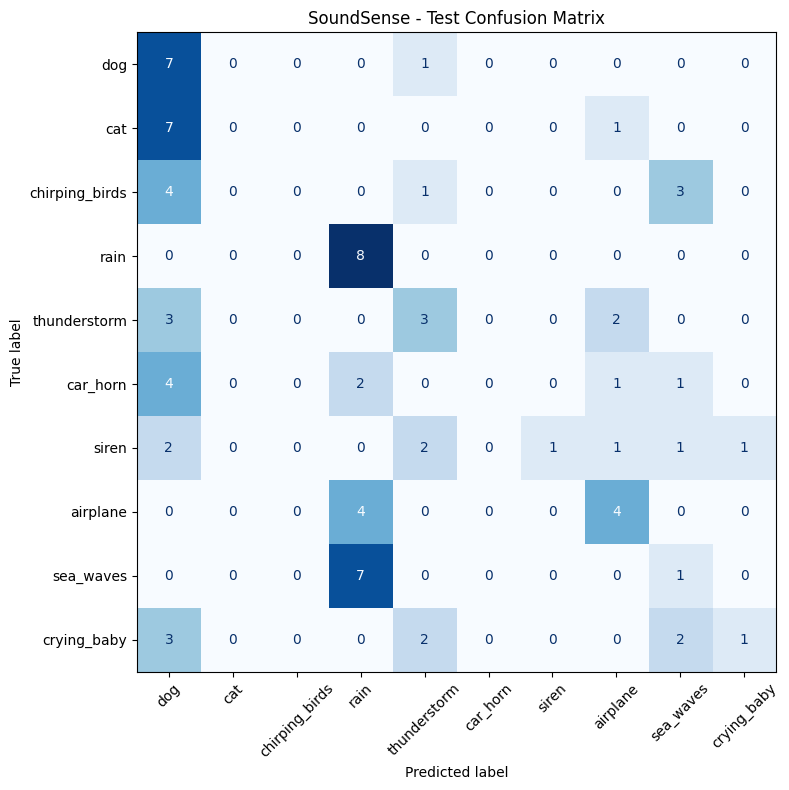

In [12]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Predict test samples
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

# Detailed performance for every class
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(categories)),
    target_names=[str(c) for c in categories],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test, y_pred,
    labels=np.arange(len(categories))
)

fig, ax = plt.subplots(figsize=(10, 8))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[str(c) for c in categories]
)
disp.plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
plt.title("SoundSense - Test Confusion Matrix")
plt.tight_layout()
plt.show()


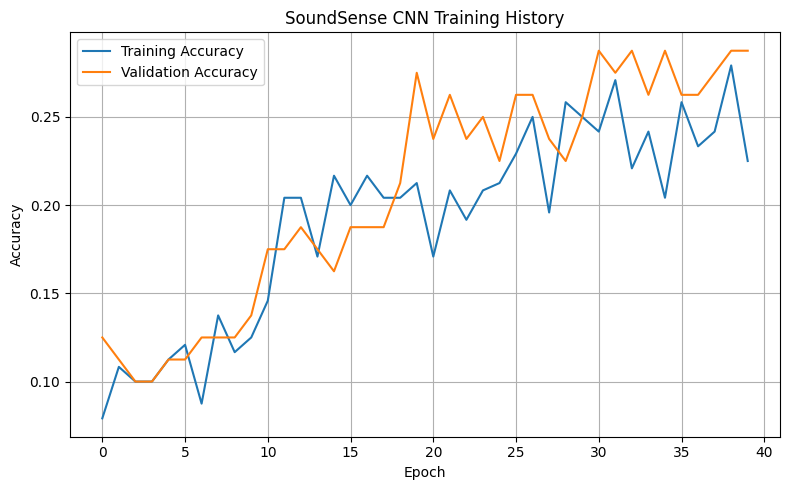

In [13]:

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("SoundSense CNN Training History")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


                precision    recall  f1-score   support

           dog       0.23      0.88      0.37         8
           cat       0.00      0.00      0.00         8
chirping_birds       0.00      0.00      0.00         8
          rain       0.38      1.00      0.55         8
  thunderstorm       0.33      0.38      0.35         8
      car_horn       0.00      0.00      0.00         8
         siren       1.00      0.12      0.22         8
      airplane       0.44      0.50      0.47         8
     sea_waves       0.12      0.12      0.12         8
   crying_baby       0.50      0.12      0.20         8

      accuracy                           0.31        80
     macro avg       0.30      0.31      0.23        80
  weighted avg       0.30      0.31      0.23        80



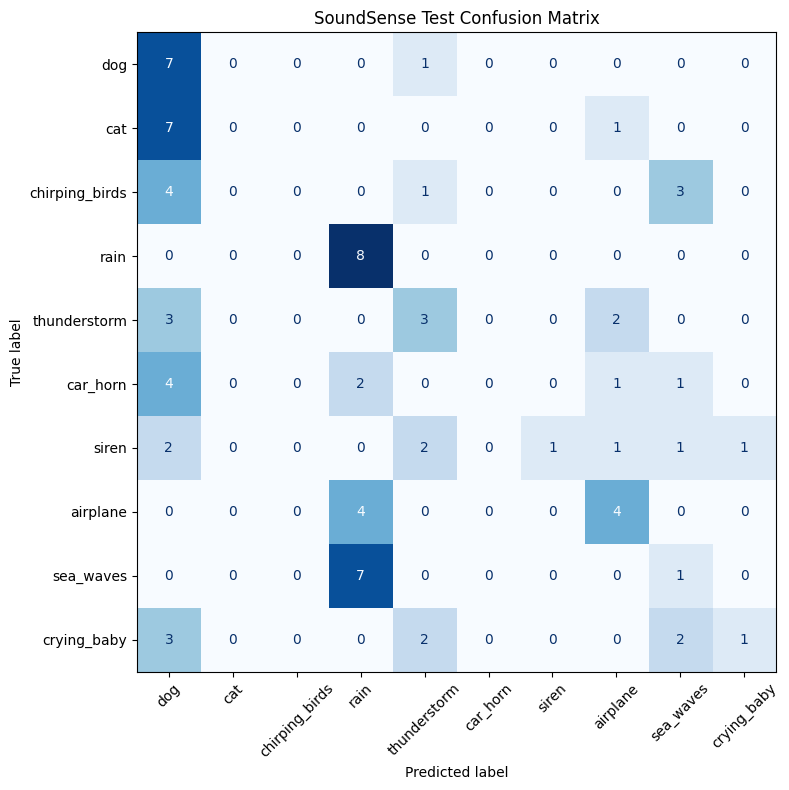

In [14]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix

y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(categories)),
    target_names=[str(c) for c in categories],
    zero_division=0
))

cm = confusion_matrix(
    y_test, y_pred,
    labels=np.arange(len(categories))
)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[str(c) for c in categories]
).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)

plt.title("SoundSense Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [15]:

!pip -q install tensorflow-hub librosa

import tensorflow as tf
import tensorflow_hub as hub
import librosa
import numpy as np
import os
from tqdm.auto import tqdm

yamnet = hub.load("https://tfhub.dev/google/yamnet/1")

print("YAMNet loaded successfully!")


/usr/local/lib/python3.13/dist-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version


YAMNet loaded successfully!


In [16]:

DATASET_PATH = "/content/ESC-50-master"
AUDIO_PATH = os.path.join(DATASET_PATH, "audio")
METADATA_PATH = os.path.join(DATASET_PATH, "meta", "esc50.csv")

import pandas as pd

df = pd.read_csv(METADATA_PATH)
df = df[df["category"].isin([str(c) for c in categories])].copy()

label_map = {str(c): i for i, c in enumerate(categories)}
df["label"] = df["category"].map(label_map)
df = df.sort_values(["fold", "filename"]).reset_index(drop=True)

embeddings = []
labels = []
audio_folds = []

for _, row in tqdm(df.iterrows(), total=len(df)):
    path = os.path.join(AUDIO_PATH, row["filename"])

    audio, sr = librosa.load(path, sr=16000, mono=True)
    audio = audio.astype(np.float32)

    # YAMNet returns frame-level embeddings
    _, frame_embeddings, _ = yamnet(audio)

    # Average frame embeddings into one vector per clip
    clip_embedding = tf.reduce_mean(
        frame_embeddings, axis=0
    ).numpy()

    embeddings.append(clip_embedding)
    labels.append(int(row["label"]))
    audio_folds.append(int(row["fold"]))

E = np.array(embeddings, dtype=np.float32)
labels = np.array(labels, dtype=np.int64)
audio_folds = np.array(audio_folds)

train = np.isin(audio_folds, [1, 2, 3])
valid = audio_folds == 4
test = audio_folds == 5

print("Embeddings:", E.shape)
print("Train:", train.sum(), "Validation:", valid.sum(),
      "Test:", test.sum())


  0%|          | 0/400 [00:00<?, ?it/s]

Embeddings: (400, 1024)
Train: 240 Validation: 80 Test: 80


In [17]:

from tensorflow import keras
from tensorflow.keras import layers, regularizers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import numpy as np

# Normalize using training data only
mean = E[train].mean(axis=0)
std = E[train].std(axis=0)
std[std < 1e-6] = 1.0

E_norm = (E - mean) / std

E_train, y_train_yam = E_norm[train], labels[train]
E_val, y_val_yam = E_norm[valid], labels[valid]
E_test, y_test_yam = E_norm[test], labels[test]

tf.keras.utils.set_random_seed(42)

yamnet_classifier = keras.Sequential([
    layers.Input(shape=(1024,)),
    layers.Dense(
        128, activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.4),
    layers.Dense(
        64, activation="relu",
        kernel_regularizer=regularizers.l2(0.001)
    ),
    layers.Dropout(0.3),
    layers.Dense(len(categories), activation="softmax")
])

yamnet_classifier.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    ),
    ModelCheckpoint(
        "/content/soundsense_yamnet_classifier.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history_yamnet = yamnet_classifier.fit(
    E_train, y_train_yam,
    validation_data=(E_val, y_val_yam),
    epochs=60,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.2958 - loss: 2.9628 - val_accuracy: 0.8000 - val_loss: 1.6224 - learning_rate: 0.0010
Epoch 2/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.5458 - loss: 1.8954 - val_accuracy: 0.8875 - val_loss: 1.2208 - learning_rate: 0.0010
Epoch 3/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7375 - loss: 1.5060 - val_accuracy: 0.8750 - val_loss: 0.7421 - learning_rate: 0.0010
Epoch 4/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8250 - loss: 0.9500 - val_accuracy: 0.8875 - val_loss: 0.6678 - learning_rate: 0.0010
Epoch 5/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.8292 - loss: 1.1809 - val_accuracy: 0.9000 - val_loss: 0.6516 - learning_rate: 0.0010
Epoch 6/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8625 - loss: 0.9460 - val_accuracy: 0.9125 - val_loss: 0.6102 - learning_rate: 0.0010
Epoch 7/60
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - accuracy: 0.8708 - loss: 0.9219 - val_acc

Final Test Accuracy: 90.00%
Test Loss: 0.7324



Classification Report:
                precision    recall  f1-score   support

           dog       1.00      0.88      0.93         8
           cat       0.67      1.00      0.80         8
chirping_birds       1.00      1.00      1.00         8
          rain       1.00      1.00      1.00         8
  thunderstorm       0.73      1.00      0.84         8
      car_horn       1.00      0.62      0.77         8
         siren       1.00      1.00      1.00         8
      airplane       1.00      0.50      0.67         8
     sea_waves       0.89      1.00      0.94         8
   crying_baby       1.00      1.00      1.00         8

      accuracy                           0.90        80
     macro avg       0.93      0.90      0.90        80
  weighted avg       0.93      0.90      0.90        80



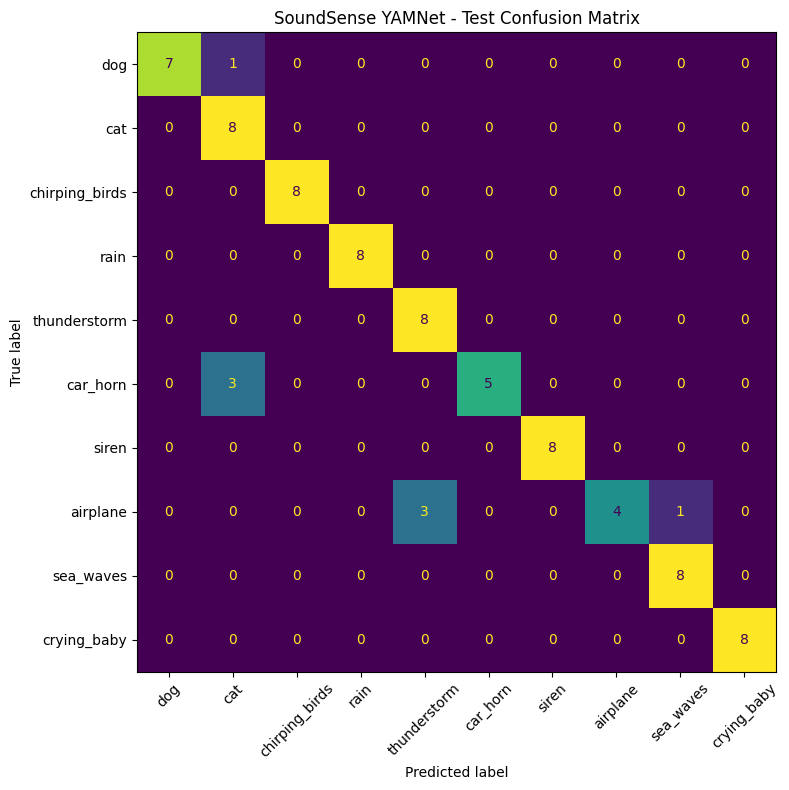

In [18]:

from tensorflow import keras
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Load best model saved during training
best_model = keras.models.load_model(
    "/content/soundsense_yamnet_classifier.keras"
)

# Evaluate on the separate test set
test_loss, test_accuracy = best_model.evaluate(
    E_test, y_test_yam, verbose=0
)

print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

# Per-class results
y_prob = best_model.predict(E_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("\nClassification Report:")
print(classification_report(
    y_test_yam,
    y_pred,
    labels=np.arange(len(categories)),
    target_names=[str(c) for c in categories],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    y_test_yam,
    y_pred,
    labels=np.arange(len(categories))
)

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=[str(c) for c in categories]
).plot(ax=ax, xticks_rotation=45, colorbar=False)

plt.title("SoundSense YAMNet - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [19]:

import json
import numpy as np

# Save the best trained classifier
best_model.save("/content/soundsense_yamnet_classifier.keras")

# Save normalization values
np.savez(
    "/content/soundsense_normalization.npz",
    mean=mean,
    std=std
)

# Save the exact class order
with open("/content/soundsense_categories.json", "w") as f:
    json.dump([str(c) for c in categories], f, indent=2)

print("SoundSense model and supporting files saved!")
print("1. soundsense_yamnet_classifier.keras")
print("2. soundsense_normalization.npz")
print("3. soundsense_categories.json")


SoundSense model and supporting files saved!
1. soundsense_yamnet_classifier.keras
2. soundsense_normalization.npz
3. soundsense_categories.json


In [20]:

!pip -q install tensorflow-hub librosa ipywidgets

import tensorflow as tf
import tensorflow_hub as hub
import librosa
import numpy as np
import json
import os
from google.colab import files
from IPython.display import display, Audio

# Load saved classifier and supporting files
model = tf.keras.models.load_model(
    "/content/soundsense_yamnet_classifier.keras"
)

norm_data = np.load("/content/soundsense_normalization.npz")
mean = norm_data["mean"]
std = norm_data["std"]

with open("/content/soundsense_categories.json", "r") as f:
    categories = json.load(f)

# Load pretrained YAMNet feature extractor
yamnet = hub.load("https://tfhub.dev/google/yamnet/1")

print("SoundSense is ready!")
print("Supported sounds:", ", ".join(categories))


SoundSense is ready!
Supported sounds: dog, cat, chirping_birds, rain, thunderstorm, car_horn, siren, airplane, sea_waves, crying_baby


In [21]:

from google.colab import files
from IPython.display import display, Audio
import numpy as np
import librosa
import tensorflow as tf

# Audio file upload karein
uploaded = files.upload()

for filename in uploaded:
    if not filename.lower().endswith((".wav", ".mp3", ".flac", ".ogg")):
        print("Unsupported audio format:", filename)
        continue

    # Audio ko 16 kHz mono mein convert karein
    audio, sr = librosa.load(filename, sr=16000, mono=True)

    # YAMNet se audio features extract karein
    _, frame_embeddings, _ = yamnet(audio)
    embedding = tf.reduce_mean(frame_embeddings, axis=0).numpy()

    # Training wali normalization apply karein
    embedding = (embedding - mean) / std
    embedding = embedding.reshape(1, 1024)

    # Sound predict karein
    probabilities = model.predict(embedding, verbose=0)[0]
    predicted_index = int(np.argmax(probabilities))

    print("\nAudio file:", filename)
    print("Predicted sound:", categories[predicted_index])
    print(f"Confidence: {probabilities[predicted_index] * 100:.2f}%")

    print("\nTop 3 predictions:")
    for idx in np.argsort(probabilities)[-3:][::-1]:
        print(f"{categories[idx]}: {probabilities[idx] * 100:.2f}%")

    display(Audio(audio, rate=16000))


Saving wav.mp3.wav (online-audio-converter.com).wav to wav.mp3.wav (online-audio-converter.com).wav

Audio file: wav.mp3.wav (online-audio-converter.com).wav
Predicted sound: crying_baby
Confidence: 100.00%

Top 3 predictions:
crying_baby: 100.00%
dog: 0.00%
cat: 0.00%


In [22]:

from google.colab import drive
import os
import shutil

drive.mount('/content/drive')

save_dir = '/content/drive/MyDrive/SoundSense'
os.makedirs(save_dir, exist_ok=True)

files_to_save = [
    '/content/soundsense_yamnet_classifier.keras',
    '/content/soundsense_normalization.npz',
    '/content/soundsense_categories.json'
]

for file_path in files_to_save:
    if os.path.exists(file_path):
        shutil.copy2(file_path, save_dir)
        print("Saved:", os.path.basename(file_path))
    else:
        print("File not found:", file_path)

print("\nSoundSense files Google Drive mein save ho gayi hain.")


Mounted at /content/drive
Saved: soundsense_yamnet_classifier.keras
Saved: soundsense_normalization.npz
Saved: soundsense_categories.json

SoundSense files Google Drive mein save ho gayi hain.
